# ICBHI 2017 Respiratory Sound – Full Research Pipeline (PyTorch, Kaggle)
Dataset: `nimalanparameshwaran/icbhi-2017-challenge-respiratory-sound-database`

Setup: Kaggle Notebook -> Add Data (ei dataset) -> Accelerator: GPU (T4/P100). Internet lagbe na.

Task: respiratory *cycle* classification -> 4 class (Normal / Crackle / Wheeze / Both)
Metrics: Sp, Se, ICBHI Score = (Sp+Se)/2, Macro-F1, Acc

Parts:
1 Dataset exploration | 2 Audio preprocessing | 3 Patient-independent split | 4 Baseline CNN
5 ResNet / CNN-BiLSTM | 6 Proposed CNN-Transformer | 7 Noise robustness | 8 Explainable AI
9 Ablation | 10 Statistical analysis

NOTE: CFG.QUICK = True dile sob kichu ~10 minute e dry-run hoy. Final result er jonno False + SEEDS=[0,1,2] dao.

In [4]:
import os, glob, re, random, copy, time, math, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
from scipy import stats
from scipy.signal import butter, sosfiltfilt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")


class CFG:
    ROOT = "/kaggle/input/datasets/husninm/icbhi-2017-challenge"   # Part 1 e auto-detect hoy
    WORK = "/kaggle/working"
    SR = 4000                      # resample rate
    DUR = 4.0                      # seconds per cycle (fixed length)
    N_SAMPLES = int(SR * DUR)
    N_FFT, HOP, N_MELS, FMIN, FMAX = 512, 64, 64, 50, 2000
    CLASSES = ["Normal", "Crackle", "Wheeze", "Both"]
    N_FOLDS = 5
    SEEDS = [0]                    # final: [0, 1, 2] (more paired samples for statistics)
    EPOCHS = 30
    BATCH = 64
    LR = 1e-3
    WD = 1e-2
    PATIENCE = 12
    QUICK = True                   # <<< False kore full run koro
    FOLDS_TO_RUN = list(range(5))


if CFG.QUICK:
    CFG.EPOCHS, CFG.FOLDS_TO_RUN, CFG.PATIENCE = 3, [0, 1], 3

DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs(CFG.WORK, exist_ok=True)


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


print("Device:", DEV, "| QUICK:", CFG.QUICK)

Device: cuda | QUICK: True


# 1. Dataset exploration

In [5]:
# ---------- ROOT auto-detect ----------
_cands = ["/kaggle/input/datasets/husninm/icbhi-2017-challenge", "/kaggle/input"]
CFG.ROOT = next(p for p in _cands if os.path.exists(p))
print("ROOT:", CFG.ROOT)

wav_paths = sorted(glob.glob(f"{CFG.ROOT}/**/*.wav", recursive=True))
all_txt   = glob.glob(f"{CFG.ROOT}/**/*.txt", recursive=True)
all_csv   = glob.glob(f"{CFG.ROOT}/**/*.csv", recursive=True)
print(f"{len(wav_paths)} wav | {len(all_txt)} txt | {len(all_csv)} csv")
assert wav_paths, "Kono .wav paoa jai nai. Sidebar theke dataset add kora ache kina dekho."

# annotation txt: stem -> path (wav er same naam er txt)
txt_by_stem = {os.path.splitext(os.path.basename(p))[0]: p for p in all_txt}


# ---------- patient diagnosis (robust) ----------
def load_diagnosis():
    cands = [p for p in all_csv + all_txt if "diagnosis" in os.path.basename(p).lower()]
    cands += [p for p in all_csv if p not in cands]          # fallback: jekono csv
    for f in cands:
        try:
            d = pd.read_csv(f, sep=None, engine="python", header=None)
        except Exception:
            continue
        if d.shape[1] < 2: continue
        d = d.iloc[:, :2].copy(); d.columns = ["pid", "diagnosis"]
        d = d[pd.to_numeric(d["pid"], errors="coerce").notna()]
        if len(d) >= 50:                                      # ~126 patient thakar kotha
            d["pid"] = d["pid"].astype(int); d["diagnosis"] = d["diagnosis"].astype(str).str.strip()
            print("Diagnosis file:", f, "->", len(d), "patients")
            return d
    print("WARNING: diagnosis file paoa jai nai, diagnosis = 'Unknown' hobe")
    return pd.DataFrame(columns=["pid", "diagnosis"])


diag_df = load_diagnosis()
diag_map = dict(zip(diag_df.pid, diag_df.diagnosis))

# ---------- recording metadata: PID_recIdx_chestLoc_acqMode_equipment ----------
pat = re.compile(r"^(\d+)_([^_]+)_([^_]+)_([^_]+)_(.+)$")
rec_rows, skipped = [], []
for p in wav_paths:
    stem = os.path.splitext(os.path.basename(p))[0]
    txt = txt_by_stem.get(stem)
    if txt is None:
        skipped.append(stem); continue
    m = pat.match(stem)
    mp = re.match(r"^(\d+)", stem)
    rec_rows.append(dict(path=p, txt=txt, stem=stem, pid=int(mp.group(1)) if mp else -1,
                         rec_idx=m[2] if m else "NA", loc=m[3] if m else "NA",
                         mode=m[4] if m else "NA", dev=m[5] if m else "NA"))
rec_df = pd.DataFrame(rec_rows)
print(f"Usable recordings: {len(rec_df)} | skipped (annotation nai): {len(skipped)}", skipped[:5])
assert len(rec_df) > 0, "Wav gulor sathe match kora annotation .txt paoa jai nai"

# ---------- cycle-level annotation ----------
cyc_rows = []
for r in rec_df.itertuples():
    a = pd.read_csv(r.txt, sep=r"\s+", header=None)
    a = a.iloc[:, :4].apply(pd.to_numeric, errors="coerce").dropna()
    a.columns = ["start", "end", "crackle", "wheeze"]
    for i, c in enumerate(a.itertuples()):
        cyc_rows.append(dict(path=r.path, stem=r.stem, pid=r.pid, loc=r.loc, mode=r.mode, dev=r.dev,
                             cyc_idx=i, start=c.start, end=c.end, crackle=int(c.crackle), wheeze=int(c.wheeze)))
ann_df = pd.DataFrame(cyc_rows)
ann_df["label"] = ann_df.crackle + 2 * ann_df.wheeze          # 0 N, 1 C, 2 W, 3 Both
ann_df["dur"] = ann_df.end - ann_df.start
ann_df["diagnosis"] = ann_df.pid.map(diag_map).fillna("Unknown")
print(ann_df.head())

print("\nPatients:", ann_df.pid.nunique(), "| Recordings:", len(rec_df), "| Cycles:", len(ann_df))
print("Total annotated duration (h): %.2f" % (ann_df.dur.sum() / 3600))
print("\nCycle class distribution:\n", ann_df.label.map(dict(enumerate(CFG.CLASSES))).value_counts())
print("\nCycle duration (s):\n", ann_df.dur.describe())
print("\nPatient diagnosis:\n", diag_df.diagnosis.value_counts() if len(diag_df) else "n/a")

ROOT: /kaggle/input/datasets/husninm/icbhi-2017-challenge
920 wav | 922 txt | 0 csv
Usable recordings: 920 | skipped (annotation nai): 0 []
                                                path                    stem  \
0  /kaggle/input/datasets/husninm/icbhi-2017-chal...  101_1b1_Al_sc_Meditron   
1  /kaggle/input/datasets/husninm/icbhi-2017-chal...  101_1b1_Al_sc_Meditron   
2  /kaggle/input/datasets/husninm/icbhi-2017-chal...  101_1b1_Al_sc_Meditron   
3  /kaggle/input/datasets/husninm/icbhi-2017-chal...  101_1b1_Al_sc_Meditron   
4  /kaggle/input/datasets/husninm/icbhi-2017-chal...  101_1b1_Al_sc_Meditron   

   pid loc mode       dev  cyc_idx  start    end  crackle  wheeze  label  \
0  101  Al   sc  Meditron        0  0.036  0.579        0       0      0   
1  101  Al   sc  Meditron        1  0.579  2.450        0       0      0   
2  101  Al   sc  Meditron        2  2.450  3.893        0       0      0   
3  101  Al   sc  Meditron        3  3.893  5.793        0       0      0   

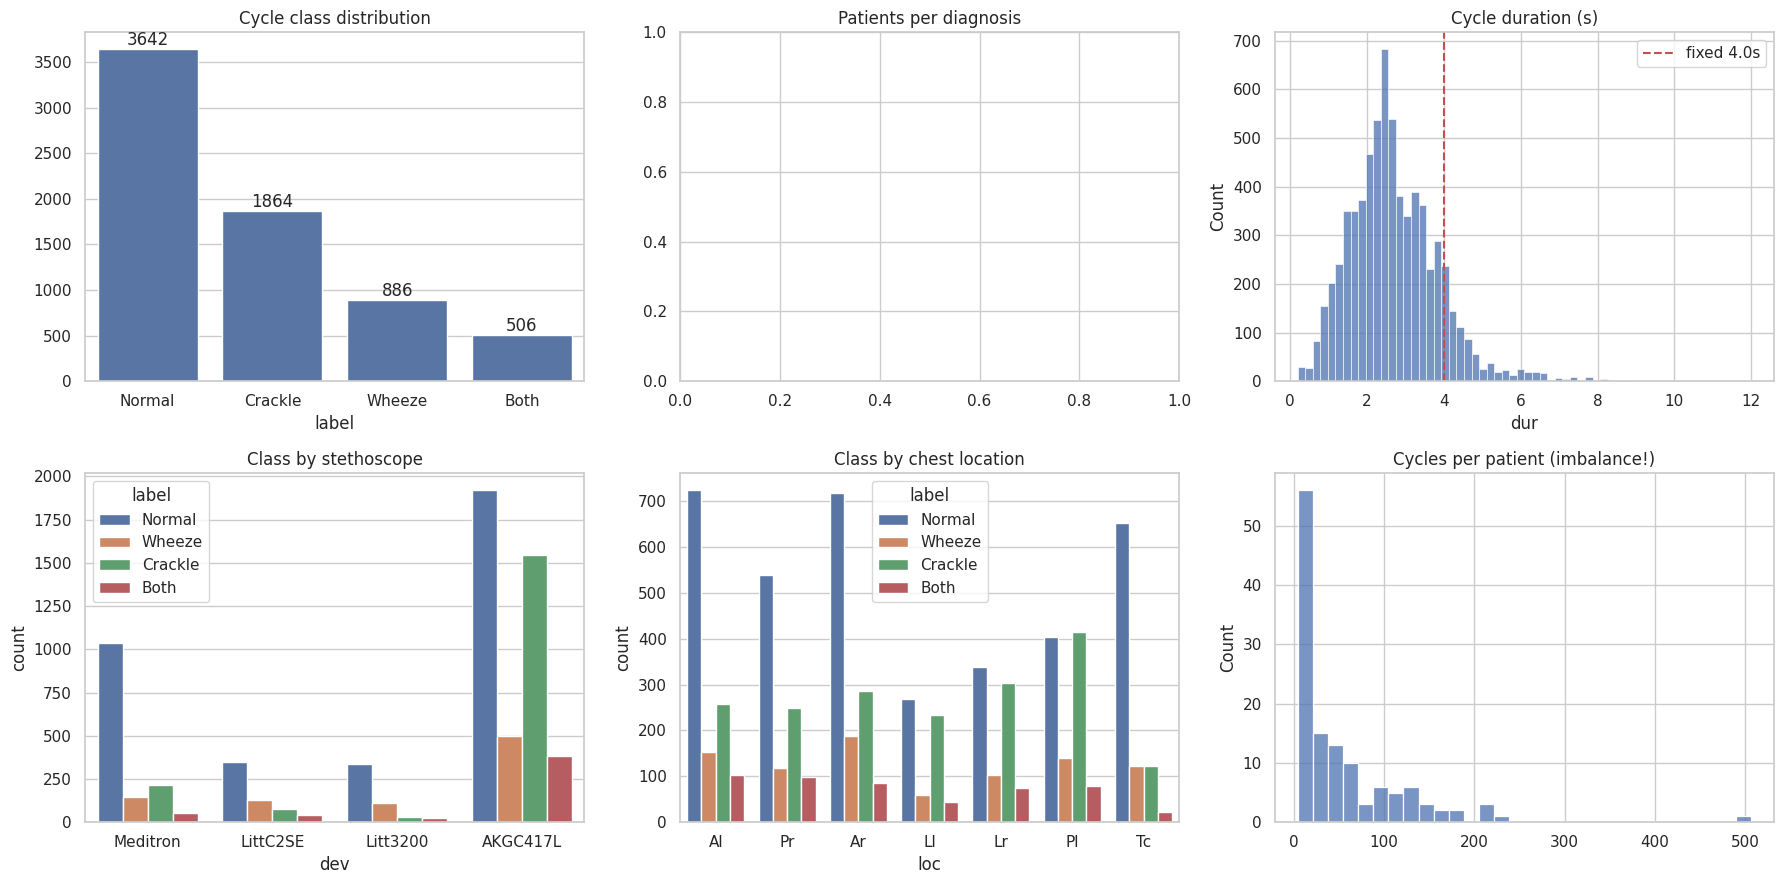

label      Both  Crackle  Normal  Wheeze
diagnosis                               
Unknown     506     1864    3642     886

Sample rates in raw files (first 10):
[44100, 44100, 44100, 44100, 4000, 4000, 4000, 4000, 4000, 4000]


In [6]:
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
cnt = ann_df.label.map(dict(enumerate(CFG.CLASSES))).value_counts().reindex(CFG.CLASSES)
sns.barplot(x=cnt.index, y=cnt.values, ax=ax[0, 0]); ax[0, 0].set_title("Cycle class distribution")
for i, v in enumerate(cnt.values): ax[0, 0].text(i, v, str(v), ha="center", va="bottom")

if len(diag_df):
    dd = diag_df.diagnosis.value_counts()
    sns.barplot(y=dd.index, x=dd.values, ax=ax[0, 1])
ax[0, 1].set_title("Patients per diagnosis")

sns.histplot(ann_df.dur.clip(upper=12), bins=60, ax=ax[0, 2])
ax[0, 2].axvline(CFG.DUR, c="r", ls="--", label=f"fixed {CFG.DUR}s"); ax[0, 2].legend()
ax[0, 2].set_title("Cycle duration (s)")

sns.countplot(data=ann_df, x="dev", hue=ann_df.label.map(dict(enumerate(CFG.CLASSES))), ax=ax[1, 0])
ax[1, 0].set_title("Class by stethoscope")

sns.countplot(data=ann_df, x="loc", hue=ann_df.label.map(dict(enumerate(CFG.CLASSES))), ax=ax[1, 1])
ax[1, 1].set_title("Class by chest location")

pc = ann_df.groupby("pid").size()
sns.histplot(pc, bins=30, ax=ax[1, 2]); ax[1, 2].set_title("Cycles per patient (imbalance!)")
plt.tight_layout(); plt.savefig(f"{CFG.WORK}/fig_eda.png", dpi=150); plt.show()

ct = pd.crosstab(ann_df.diagnosis, ann_df.label.map(dict(enumerate(CFG.CLASSES))))
print(ct)
print("\nSample rates in raw files (first 10):")
print([librosa.get_samplerate(p) for p in wav_paths[:10]])

# 2. Audio preprocessing
- resample 4 kHz, Butterworth band-pass 50–1800 Hz (zero-phase)
- respiratory cycle segmentation using annotation (start/end)
- fixed length 4 s: center-crop (lomba) / circular repeat (choto)
- per-cycle zero-mean + peak normalisation
- GPU log-Mel frontend + SpecAugment (training only)

In [ ]:
SOS = butter(4, [50, 1800], btype="band", fs=CFG.SR, output="sos")
MIN_LEN = int(0.2 * CFG.SR)


def fix_length(x, n):
    if len(x) >= n:
        s = (len(x) - n) // 2
        return x[s:s + n]
    return np.tile(x, int(np.ceil(n / len(x))))[:n]


def norm_wave(x):
    x = x - x.mean()
    return x / (np.abs(x).max() + 1e-8)


cache_X, cache_meta = f"{CFG.WORK}/icbhi_X.npy", f"{CFG.WORK}/icbhi_meta.csv"
if os.path.exists(cache_X) and os.path.exists(cache_meta):
    X = np.load(cache_X); meta = pd.read_csv(cache_meta)
else:
    Xs, keep = [], []
    for path, g in ann_df.groupby("path"):
        x, _ = librosa.load(path, sr=CFG.SR, mono=True)
        x = sosfiltfilt(SOS, x)
        for idx, c in g.iterrows():
            seg = x[int(c.start * CFG.SR): int(c.end * CFG.SR)]
            if len(seg) < MIN_LEN: continue
            Xs.append(norm_wave(fix_length(seg, CFG.N_SAMPLES)).astype(np.float32)); keep.append(idx)
    X = np.stack(Xs); meta = ann_df.loc[keep].reset_index(drop=True)
    np.save(cache_X, X); meta.to_csv(cache_meta, index=False)

Y = meta.label.values.astype(np.int64)
PID = meta.pid.values.astype(np.int64)
N = len(Y)
print("X:", X.shape, "| labels:", np.bincount(Y), "| patients:", len(np.unique(PID)))

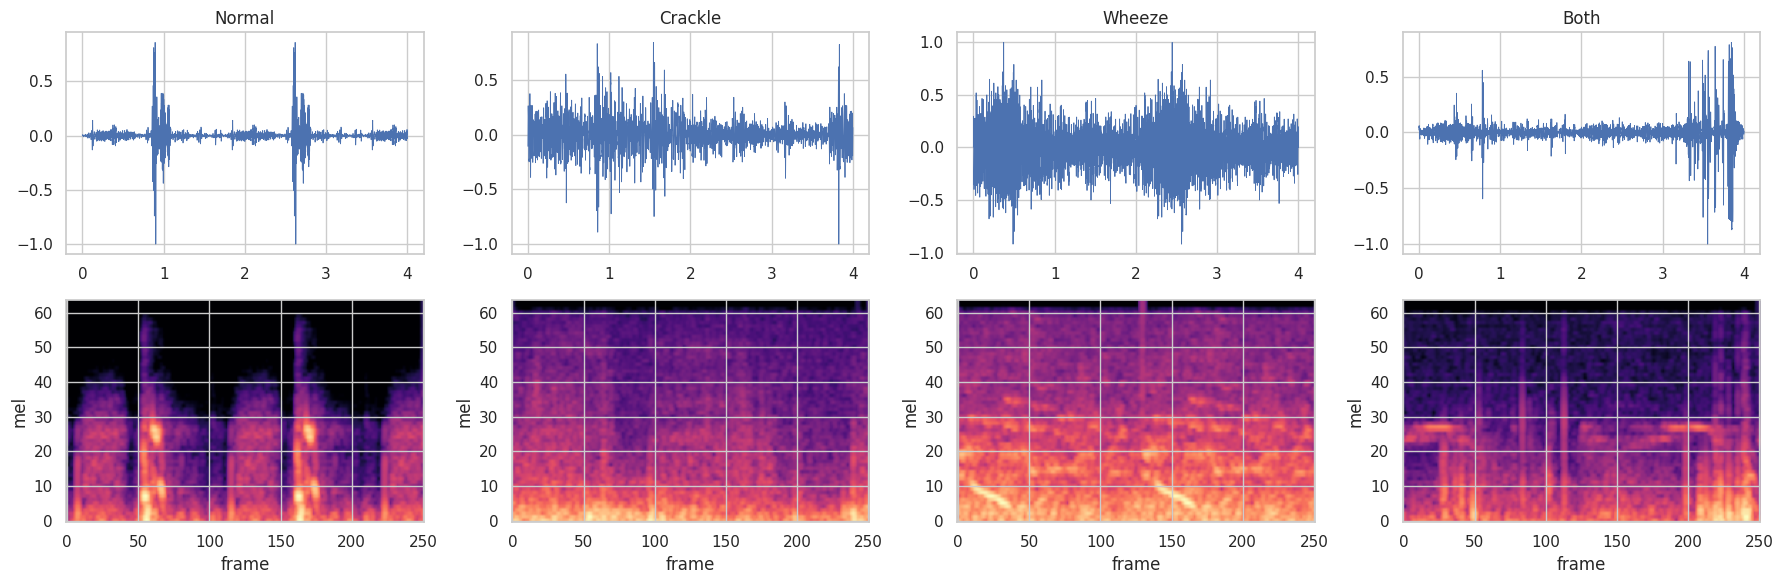

In [8]:
# ---- GPU log-Mel frontend
def spec_augment(x, f_max=10, t_max=25, n_f=2, n_t=2):
    B, _, Fq, T = x.shape
    for dim, mx, n in ((2, f_max, n_f), (3, t_max, n_t)):
        L = Fq if dim == 2 else T
        ar = torch.arange(L, device=x.device).view(1, 1, L, 1) if dim == 2 else \
            torch.arange(L, device=x.device).view(1, 1, 1, L)
        for _ in range(n):
            w = torch.randint(0, mx + 1, (B, 1, 1, 1), device=x.device)
            s = (torch.rand(B, 1, 1, 1, device=x.device) * (L - w)).long()
            x = x.masked_fill((ar >= s) & (ar < s + w), 0.0)
    return x


class LogMel(nn.Module):
    def __init__(self, specaug=True):
        super().__init__()
        self.mel = torchaudio.transforms.MelSpectrogram(
            sample_rate=CFG.SR, n_fft=CFG.N_FFT, hop_length=CFG.HOP, f_min=CFG.FMIN,
            f_max=CFG.FMAX, n_mels=CFG.N_MELS, power=2.0)
        self.db = torchaudio.transforms.AmplitudeToDB("power", top_db=80.0)
        self.specaug = specaug

    def forward(self, wav):                                   # (B, L) -> (B,1,F,T)
        with torch.autocast(device_type=wav.device.type, enabled=False):
            x = self.db(self.mel(wav.float()))
            x = (x - x.mean((1, 2), keepdim=True)) / (x.std((1, 2), keepdim=True) + 1e-5)
            x = x.unsqueeze(1)
            if self.training and self.specaug:
                x = spec_augment(x)
        return x


# ---- noise utilities (Part 7 e use hobe)
def make_noise(shape, kind, device, gen=None):
    n = torch.randn(shape, device=device, generator=gen)
    if kind in ("pink", "brown"):
        Xf = torch.fft.rfft(n, dim=-1)
        f = torch.arange(Xf.shape[-1], device=device).clamp(min=1).float()
        Xf = Xf / (torch.sqrt(f) if kind == "pink" else f)
        n = torch.fft.irfft(Xf, n=shape[-1], dim=-1)
    return n


def add_noise(x, snr_db, kind="white", gen=None):
    n = make_noise(x.shape, kind, x.device, gen)
    snr = torch.as_tensor(snr_db, device=x.device, dtype=x.dtype)
    if snr.ndim == 0: snr = snr.expand(x.size(0), 1)
    px, pn = x.pow(2).mean(-1, keepdim=True), n.pow(2).mean(-1, keepdim=True)
    return x + torch.sqrt(px / (pn * 10 ** (snr / 10) + 1e-12)) * n


XG = torch.from_numpy(X).to(DEV)
YG = torch.from_numpy(Y).to(DEV)

# ---- visualise: waveform + log-Mel per class
fe = LogMel().to(DEV).eval()
fig, ax = plt.subplots(2, 4, figsize=(18, 6))
for c in range(4):
    i = np.random.RandomState(0).choice(np.where(Y == c)[0])
    ax[0, c].plot(np.arange(CFG.N_SAMPLES) / CFG.SR, X[i], lw=.6); ax[0, c].set_title(CFG.CLASSES[c])
    with torch.no_grad(): s = fe(XG[i:i + 1])[0, 0].cpu().numpy()
    ax[1, c].imshow(s, origin="lower", aspect="auto", cmap="magma"); ax[1, c].set_xlabel("frame"); ax[1, c].set_ylabel("mel")
plt.tight_layout(); plt.savefig(f"{CFG.WORK}/fig_preproc.png", dpi=150); plt.show()

# 3. Patient-independent data splitting
`StratifiedGroupKFold` – ek patient er shob cycle ekই fold e thake (no leakage).
Fold k = test, fold k+1 = validation, baki = train.

In [9]:
from sklearn.model_selection import StratifiedGroupKFold


def make_folds(seed, n_folds=CFG.N_FOLDS):
    sgkf = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    parts = [te for _, te in sgkf.split(np.zeros(N), Y, groups=PID)]
    folds = []
    for k in range(n_folds):
        te, va = parts[k], parts[(k + 1) % n_folds]
        tr = np.concatenate([parts[j] for j in range(n_folds) if j not in (k, (k + 1) % n_folds)])
        # --- leakage check
        assert not (set(PID[tr]) & set(PID[va])) and not (set(PID[tr]) & set(PID[te])) \
            and not (set(PID[va]) & set(PID[te])), "PATIENT LEAKAGE!"
        folds.append((tr, va, te))
    return folds


_f = make_folds(0)
rows = []
for k, (tr, va, te) in enumerate(_f):
    for nm, ix in (("train", tr), ("val", va), ("test", te)):
        rows.append(dict(fold=k, split=nm, cycles=len(ix), patients=len(set(PID[ix])),
                         **{CFG.CLASSES[c]: int((Y[ix] == c).sum()) for c in range(4)}))
split_df = pd.DataFrame(rows)
print(split_df.to_string(index=False))
print("\n✔ No patient overlap between train / val / test in any fold.")

 fold split  cycles  patients  Normal  Crackle  Wheeze  Both
    0 train    4874        78    2582     1313     608   371
    0   val    1120        27     571      272     181    96
    0  test     904        21     489      279      97    39
    1 train    3650        74    2087      837     456   270
    1   val    2128        25     984      755     249   140
    1  test    1120        27     571      272     181    96
    2 train    3331        75    1783      854     483   211
    2   val    1439        26     875      255     154   155
    2  test    2128        25     984      755     249   140
    3 train    4152        73    2044     1306     527   275
    3   val    1307        27     723      303     205    76
    3  test    1439        26     875      255     154   155
    4 train    4687        78    2430     1282     584   391
    4   val     904        21     489      279      97    39
    4  test    1307        27     723      303     205    76

✔ No patient overlap be

# 4. Metrics, training engine, Baseline CNN

In [10]:
def cm_metrics(cm):
    cm = np.asarray(cm).reshape(4, 4).astype(float)
    sp = cm[0, 0] / max(cm[0].sum(), 1)
    se = np.trace(cm[1:, 1:]) / max(cm[1:].sum(), 1)
    tp = np.diag(cm)
    prec = tp / np.maximum(cm.sum(0), 1); rec = tp / np.maximum(cm.sum(1), 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    return dict(Sp=sp, Se=se, Score=(sp + se) / 2, Acc=tp.sum() / max(cm.sum(), 1),
                MacroF1=f1.mean(), BalAcc=rec.mean())


def metrics(y, p):
    return cm_metrics(np.bincount(y * 4 + p, minlength=16))


# ---- building blocks
class SE(nn.Module):
    def __init__(self, c, r=8):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(c, max(c // r, 4)), nn.ReLU(), nn.Linear(max(c // r, 4), c), nn.Sigmoid())

    def forward(self, x):
        return x * self.fc(x.mean((2, 3)))[:, :, None, None]


class ConvBlock(nn.Module):
    def __init__(self, cin, cout, n=1, pool=(2, 2), se=False, drop=0.0):
        super().__init__()
        L = []
        for i in range(n):
            L += [nn.Conv2d(cin if i == 0 else cout, cout, 3, padding=1, bias=False),
                  nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]
        if se: L.append(SE(cout))
        if pool: L.append(nn.MaxPool2d(pool))
        if drop: L.append(nn.Dropout2d(drop))
        self.net = nn.Sequential(*L)

    def forward(self, x):
        return self.net(x)


class Base(nn.Module):
    """wav (B,L) -> logits. forward_spec() XAI er jonno alada kora."""
    def forward(self, wav):
        return self.forward_spec(self.frontend(wav))


class BaselineCNN(Base):
    def __init__(self, drop=0.3):
        super().__init__()
        self.frontend = LogMel()
        self.features = nn.Sequential(ConvBlock(1, 16), ConvBlock(16, 32), ConvBlock(32, 64), ConvBlock(64, 128))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(drop), nn.Linear(128, 4))

    @property
    def cam_layer(self): return self.features

    def forward_spec(self, x): return self.head(self.features(x))


# ---- training engine (whole dataset GPU te thake -> DataLoader lagbe na)
def augment_wave(x, noise_aug=False):
    s = random.randint(-CFG.N_SAMPLES // 4, CFG.N_SAMPLES // 4)
    x = torch.roll(x, s, dims=1)
    if noise_aug:
        B = x.size(0)
        m = torch.rand(B, 1, device=x.device) < 0.5
        snr = torch.empty(B, 1, device=x.device).uniform_(0, 20)
        x = torch.where(m, add_noise(x, snr, random.choice(["white", "pink"])), x)
    return x


@torch.no_grad()
def predict(model, idx, noise=None, bs=256):
    """noise = (kind, snr_db) or None. returns softmax probs (n,4)."""
    model.eval(); out = []
    gen = None
    if noise is not None:
        gen = torch.Generator(device=DEV); gen.manual_seed(1234)     # reproducible noise
    for i in range(0, len(idx), bs):
        xb = XG[torch.as_tensor(idx[i:i + bs], device=DEV)]
        if noise is not None: xb = add_noise(xb, noise[1], noise[0], gen)
        with torch.autocast(device_type=DEV.type, dtype=torch.float16, enabled=DEV.type == "cuda"):
            lo = model(xb)
        out.append(F.softmax(lo.float(), 1).cpu())
    return torch.cat(out).numpy()


ARCH = {}  # arch registry (neeche fill hobe)


def build_model(arch, **kw):
    return ARCH[arch](**kw)


def train_model(spec, tr, va, seed, verbose=False):
    tk = dict(specaug=True, noise_aug=False, class_weight=True, label_smooth=0.05, epochs=CFG.EPOCHS)
    tk.update(spec.get("train", {}))
    set_seed(seed)
    model = build_model(spec["arch"], **spec.get("model", {})).to(DEV)
    model.frontend.specaug = tk["specaug"]
    w = None
    if tk["class_weight"]:
        cnt = np.bincount(Y[tr], minlength=4)
        w = torch.tensor((cnt.sum() / (4 * np.maximum(cnt, 1))) ** 0.5, dtype=torch.float32, device=DEV)
    crit = nn.CrossEntropyLoss(weight=w, label_smoothing=tk["label_smooth"])
    opt = torch.optim.AdamW(model.parameters(), lr=CFG.LR, weight_decay=CFG.WD)
    steps = math.ceil(len(tr) / CFG.BATCH) * tk["epochs"]
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG.LR, total_steps=steps, pct_start=0.2)
    scaler = torch.cuda.amp.GradScaler(enabled=DEV.type == "cuda")
    best, best_state, bad, hist = -1, None, 0, []
    for ep in range(tk["epochs"]):
        model.train()
        perm = torch.from_numpy(np.random.permutation(tr)).to(DEV)
        tl = 0
        for i in range(0, len(perm), CFG.BATCH):
            idx = perm[i:i + CFG.BATCH]
            if len(idx) < 4: continue
            xb, yb = augment_wave(XG[idx], tk["noise_aug"]), YG[idx]
            with torch.autocast(device_type=DEV.type, dtype=torch.float16, enabled=DEV.type == "cuda"):
                loss = crit(model(xb), yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); tl += loss.item()
        m = metrics(Y[va], predict(model, va).argmax(1))
        hist.append(dict(epoch=ep, loss=tl, **{f"val_{k}": v for k, v in m.items()}))
        if verbose: print(f"ep{ep:02d} loss {tl:.2f} val Score {m['Score']:.3f} F1 {m['MacroF1']:.3f}")
        if m["Score"] > best:
            best, bad = m["Score"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG.PATIENCE: break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), best_state


# ---- noise conditions + generic experiment runner
NOISE_CONDS = [("white", 20), ("white", 10), ("white", 5), ("white", 0), ("white", -5), ("pink", 10), ("pink", 0)]
CKPT = {}


def run_experiment(specs, noise=True, store_ckpt=False):
    rows, oof, cover, hists = [], {}, {}, {}
    for seed in CFG.SEEDS:
        folds = make_folds(seed)
        cover[seed] = np.zeros(N, bool)
        for name in specs: oof[(name, seed)] = np.zeros((N, 4), np.float32)
        for k in CFG.FOLDS_TO_RUN:
            tr, va, te = folds[k]; cover[seed][te] = True
            for name, sp in specs.items():
                t0 = time.time()
                model, h, state = train_model(sp, tr, va, seed * 100 + k)
                hists[(name, seed, k)] = h
                if store_ckpt: CKPT[(name, seed, k)] = state
                P = predict(model, te); oof[(name, seed)][te] = P
                mc = metrics(Y[te], P.argmax(1))
                rows.append(dict(model=name, seed=seed, fold=k, cond="clean", **mc))
                if noise:
                    for kind, snr in NOISE_CONDS:
                        Pn = predict(model, te, noise=(kind, snr))
                        rows.append(dict(model=name, seed=seed, fold=k, cond=f"{kind}_{snr}",
                                         **metrics(Y[te], Pn.argmax(1))))
                print(f"[seed {seed} fold {k}] {name:32s} Score {mc['Score']:.3f}"
                      f"  ({time.time() - t0:.0f}s)")
                del model; torch.cuda.empty_cache()
    return pd.DataFrame(rows), oof, cover, hists


# ---- sanity: baseline CNN, 1 fold, verbose
ARCH["cnn"] = BaselineCNN
_tr, _va, _te = make_folds(0)[0]
_m, _h, _ = train_model(dict(arch="cnn", train=dict(epochs=3)), _tr, _va, 0, verbose=True)   # quick sanity
print(metrics(Y[_te], predict(_m, _te).argmax(1)))

ep00 loss 106.62 val Score 0.418 F1 0.330
ep01 loss 99.88 val Score 0.489 F1 0.267
ep02 loss 97.91 val Score 0.517 F1 0.344
{'Sp': np.float64(0.7014314928425358), 'Se': np.float64(0.3686746987951807), 'Score': np.float64(0.5350530958188583), 'Acc': np.float64(0.5486725663716814), 'MacroF1': np.float64(0.3131830016097178), 'BalAcc': np.float64(0.322542220843934)}


# 5. ResNet and CNN-BiLSTM

In [11]:
class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.b1 = nn.BatchNorm2d(cout)
        self.c2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False); self.b2 = nn.BatchNorm2d(cout)
        self.sc = nn.Identity() if (stride == 1 and cin == cout) else \
            nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))

    def forward(self, x):
        o = F.relu(self.b1(self.c1(x)))
        o = self.b2(self.c2(o))
        return F.relu(o + self.sc(x))


class ResNetSmall(Base):
    def __init__(self, base=32, blocks=(2, 2, 2, 2), drop=0.3):
        super().__init__()
        self.frontend = LogMel()
        self.stem = nn.Sequential(nn.Conv2d(1, base, 3, 1, 1, bias=False), nn.BatchNorm2d(base), nn.ReLU())
        chans, layers, cin = [base, base * 2, base * 4, base * 8], [], base
        for i, (c, nb) in enumerate(zip(chans, blocks)):
            stage = []
            for j in range(nb):
                stage.append(BasicBlock(cin, c, 2 if (j == 0 and i > 0) else 1)); cin = c
            layers.append(nn.Sequential(*stage))
        self.layer1, self.layer2, self.layer3, self.layer4 = layers
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(drop), nn.Linear(cin, 4))

    @property
    def cam_layer(self): return self.layer4

    def forward_spec(self, x):
        x = self.layer4(self.layer3(self.layer2(self.layer1(self.stem(x)))))
        return self.head(x)


class CNNBiLSTM(Base):
    def __init__(self, hid=128, layers=2, drop=0.3):
        super().__init__()
        self.frontend = LogMel()
        self.cnn = nn.Sequential(ConvBlock(1, 32), ConvBlock(32, 64), ConvBlock(64, 128))   # F:64->8
        self.lstm = nn.LSTM(128 * (CFG.N_MELS // 8), hid, layers, batch_first=True,
                            bidirectional=True, dropout=drop)
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(4 * hid, 4))

    @property
    def cam_layer(self): return self.cnn

    def forward_spec(self, x):
        f = self.cnn(x); B, C, Fq, T = f.shape
        o, _ = self.lstm(f.permute(0, 3, 1, 2).reshape(B, T, C * Fq))
        return self.head(torch.cat([o.mean(1), o.max(1)[0]], 1))


ARCH.update(resnet=ResNetSmall, lstm=CNNBiLSTM)

# 6. Proposed CNN-Transformer
SE-augmented CNN stem (local time-frequency features) -> token projection -> [CLS] + learnable positional
embedding -> Pre-LN Transformer encoder (global temporal context) -> classification head.
Ablation er jonno sob component on/off kora jay.

In [12]:
class EncLayer(nn.Module):
    def __init__(self, d, h, ff, p):
        super().__init__()
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, h, dropout=p, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d, ff), nn.GELU(), nn.Dropout(p), nn.Linear(ff, d), nn.Dropout(p))
        self.drop = nn.Dropout(p); self.attn_w = None

    def forward(self, x):
        h = self.n1(x)
        a, w = self.attn(h, h, h, need_weights=True, average_attn_weights=True)
        self.attn_w = w.detach()                        # attention rollout (XAI) er jonno
        x = x + self.drop(a)
        return x + self.ff(self.n2(x))


class CNNTransformer(Base):
    def __init__(self, d_model=128, n_heads=4, n_layers=2, ff=256, drop=0.1,
                 use_cnn=True, use_transformer=True, use_pos=True, use_se=True, use_cls=True):
        super().__init__()
        self.frontend = LogMel()
        use_cls = use_cls and use_transformer      # transformer chara [CLS] token meaningless -> mean pooling
        self.use_pos, self.use_cls, self.use_transformer = use_pos, use_cls, use_transformer
        if use_cnn:      # F: 64->8, T: 251->62
            self.stem = nn.Sequential(ConvBlock(1, 32, 2, (2, 2), use_se),
                                      ConvBlock(32, 64, 2, (2, 2), use_se),
                                      ConvBlock(64, 128, 1, (2, 1), use_se))
        else:            # ablation: shudhu patchify (ViT-style), same token grid
            self.stem = nn.Sequential(nn.Conv2d(1, 128, (8, 4), (8, 4)), nn.BatchNorm2d(128), nn.GELU())
        n_tok = (1 + CFG.N_SAMPLES // CFG.HOP) // 4
        self.proj = nn.Sequential(nn.Linear(128 * (CFG.N_MELS // 8), d_model), nn.LayerNorm(d_model))
        self.cls = nn.Parameter(torch.zeros(1, 1, d_model)) if use_cls else None
        self.pos = nn.Parameter(torch.randn(1, n_tok + int(use_cls), d_model) * 0.02) if use_pos else None
        self.drop = nn.Dropout(drop)
        self.layers = nn.ModuleList([EncLayer(d_model, n_heads, ff, drop) for _ in range(n_layers)]) \
            if use_transformer else nn.ModuleList()
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(d_model, 4))

    @property
    def cam_layer(self): return self.stem

    def forward_spec(self, x):
        f = self.stem(x); B, C, Fq, T = f.shape
        t = self.proj(f.permute(0, 3, 1, 2).reshape(B, T, C * Fq))
        if self.cls is not None: t = torch.cat([self.cls.expand(B, -1, -1), t], 1)
        if self.pos is not None: t = t + self.pos[:, :t.size(1)]
        t = self.drop(t)
        for l in self.layers: t = l(t)
        t = self.norm(t)
        return self.head(t[:, 0] if self.cls is not None else t.mean(1))


ARCH["proposed"] = CNNTransformer

with torch.no_grad():   # shape sanity
    for a in ARCH:
        mm = build_model(a).to(DEV).eval()
        print(a, mm(XG[:2]).shape, f"{sum(p.numel() for p in mm.parameters()) / 1e6:.2f}M params")

cnn torch.Size([2, 4]) 0.10M params
resnet torch.Size([2, 4]) 2.80M params
lstm torch.Size([2, 4]) 1.67M params
proposed torch.Size([2, 4]) 0.55M params


In [13]:
# ================== MAIN BENCHMARK (clean + noisy test, 4 model + noise-aug variant) ==================
MAIN = {
    "Baseline CNN":              dict(arch="cnn"),
    "ResNet":                    dict(arch="resnet"),
    "CNN-BiLSTM":                dict(arch="lstm"),
    "CNN-Transformer (Ours)":    dict(arch="proposed"),
    "CNN-Transformer + NoiseAug": dict(arch="proposed", train=dict(noise_aug=True)),
}
main_df, main_oof, main_cover, main_hist = run_experiment(MAIN, noise=True, store_ckpt=True)
main_df.to_csv(f"{CFG.WORK}/results_main.csv", index=False)

clean = main_df[main_df.cond == "clean"]
summ = clean.groupby("model")[["Sp", "Se", "Score", "MacroF1", "Acc"]].agg(["mean", "std"]).round(3)
print(summ)

[seed 0 fold 0] Baseline CNN                     Score 0.535  (5s)
[seed 0 fold 0] ResNet                           Score 0.502  (41s)
[seed 0 fold 0] CNN-BiLSTM                       Score 0.500  (8s)
[seed 0 fold 0] CNN-Transformer (Ours)           Score 0.504  (17s)
[seed 0 fold 0] CNN-Transformer + NoiseAug       Score 0.498  (19s)
[seed 0 fold 1] Baseline CNN                     Score 0.528  (5s)
[seed 0 fold 1] ResNet                           Score 0.544  (42s)
[seed 0 fold 1] CNN-BiLSTM                       Score 0.490  (7s)
[seed 0 fold 1] CNN-Transformer (Ours)           Score 0.507  (15s)
[seed 0 fold 1] CNN-Transformer + NoiseAug       Score 0.529  (16s)
                               Sp            Se         Score        MacroF1  \
                             mean    std   mean    std   mean    std    mean   
model                                                                          
Baseline CNN                0.776  0.106  0.286  0.116  0.531  0.005   0.305   
CNN-

# 7. Noise robustness experiments
Test set e white / pink noise SNR 20→-5 dB add kore (train e noise nai). `+NoiseAug` = noise augmentation diye train.

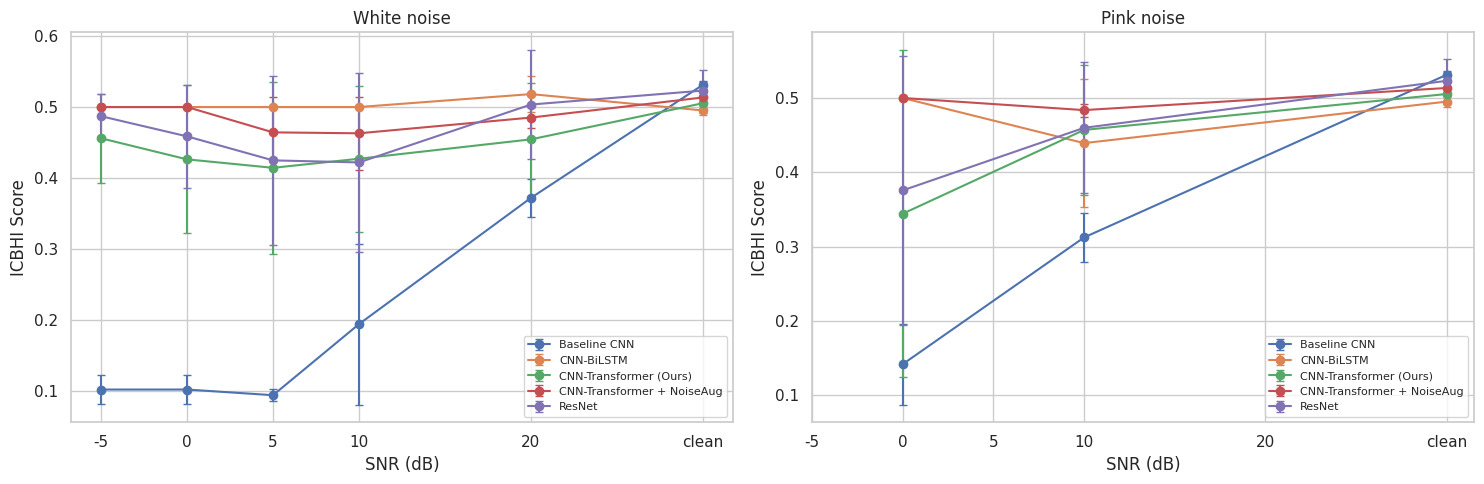

cond                        clean  white_20  white_10  white_5  white_0  \
model                                                                     
Baseline CNN                0.531     0.372     0.194    0.094    0.102   
CNN-BiLSTM                  0.495     0.518     0.500    0.500    0.500   
CNN-Transformer (Ours)      0.505     0.454     0.427    0.414    0.426   
CNN-Transformer + NoiseAug  0.513     0.485     0.463    0.464    0.500   
ResNet                      0.523     0.504     0.422    0.425    0.459   

cond                        white_-5  Drop@0dB  Drop@-5dB  
model                                                      
Baseline CNN                   0.102     0.429      0.429  
CNN-BiLSTM                     0.500    -0.005     -0.005  
CNN-Transformer (Ours)         0.456     0.079      0.049  
CNN-Transformer + NoiseAug     0.500     0.013      0.013  
ResNet                         0.487     0.064      0.036  


In [ ]:
nd = main_df.copy()
nd["kind"] = nd.cond.str.split("_").str[0]
nd["snr"] = nd.cond.map(lambda c: np.nan if c == "clean" else float(c.split("_")[1]))
clean_part = nd[nd.cond == "clean"]

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, kind in zip(ax, ["white", "pink"]):
    sub = nd[nd.kind == kind]
    for mname, g in sub.groupby("model"):
        c = clean_part[clean_part.model == mname]
        agg = g.groupby("snr").Score.agg(["mean", "std"]).sort_index()
        xs = list(agg.index) + [30]                           # 30 dB ~ "clean"
        ys = list(agg["mean"]) + [c.Score.mean()]
        es = list(agg["std"].fillna(0)) + [c.Score.std() if len(c) > 1 else 0]
        a.errorbar(xs, ys, yerr=es, marker="o", capsize=3, label=mname)
    a.set_xticks([-5, 0, 5, 10, 20, 30]); a.set_xticklabels(["-5", "0", "5", "10", "20", "clean"])
    a.set_xlabel("SNR (dB)"); a.set_ylabel("ICBHI Score"); a.set_title(f"{kind.title()} noise")
    a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{CFG.WORK}/fig_noise.png", dpi=150); plt.show()

pv = nd[nd.kind.isin(["white"]) | (nd.cond == "clean")].pivot_table(index="model", columns="cond", values="Score")
cols = ["clean"] + [f"white_{s}" for s in (20, 10, 5, 0, -5)]
pv = pv[cols]; pv["Drop@0dB"] = pv["clean"] - pv["white_0"]; pv["Drop@-5dB"] = pv["clean"] - pv["white_-5"]
print(pv.round(3))

# 8. Explainable AI
- Grad-CAM (CNN stem / ResNet last stage)
- Integrated Gradients (log-Mel input)
- Attention rollout (Transformer [CLS] -> time)
- Quantitative faithfulness: deletion test (top-attribution bins mask korle prob koto kome)

XAI samples: [ 362  374 1005 1007  599  606 1682 1899] ['Normal', 'Normal', 'Crackle', 'Crackle', 'Wheeze', 'Wheeze', 'Both', 'Both']


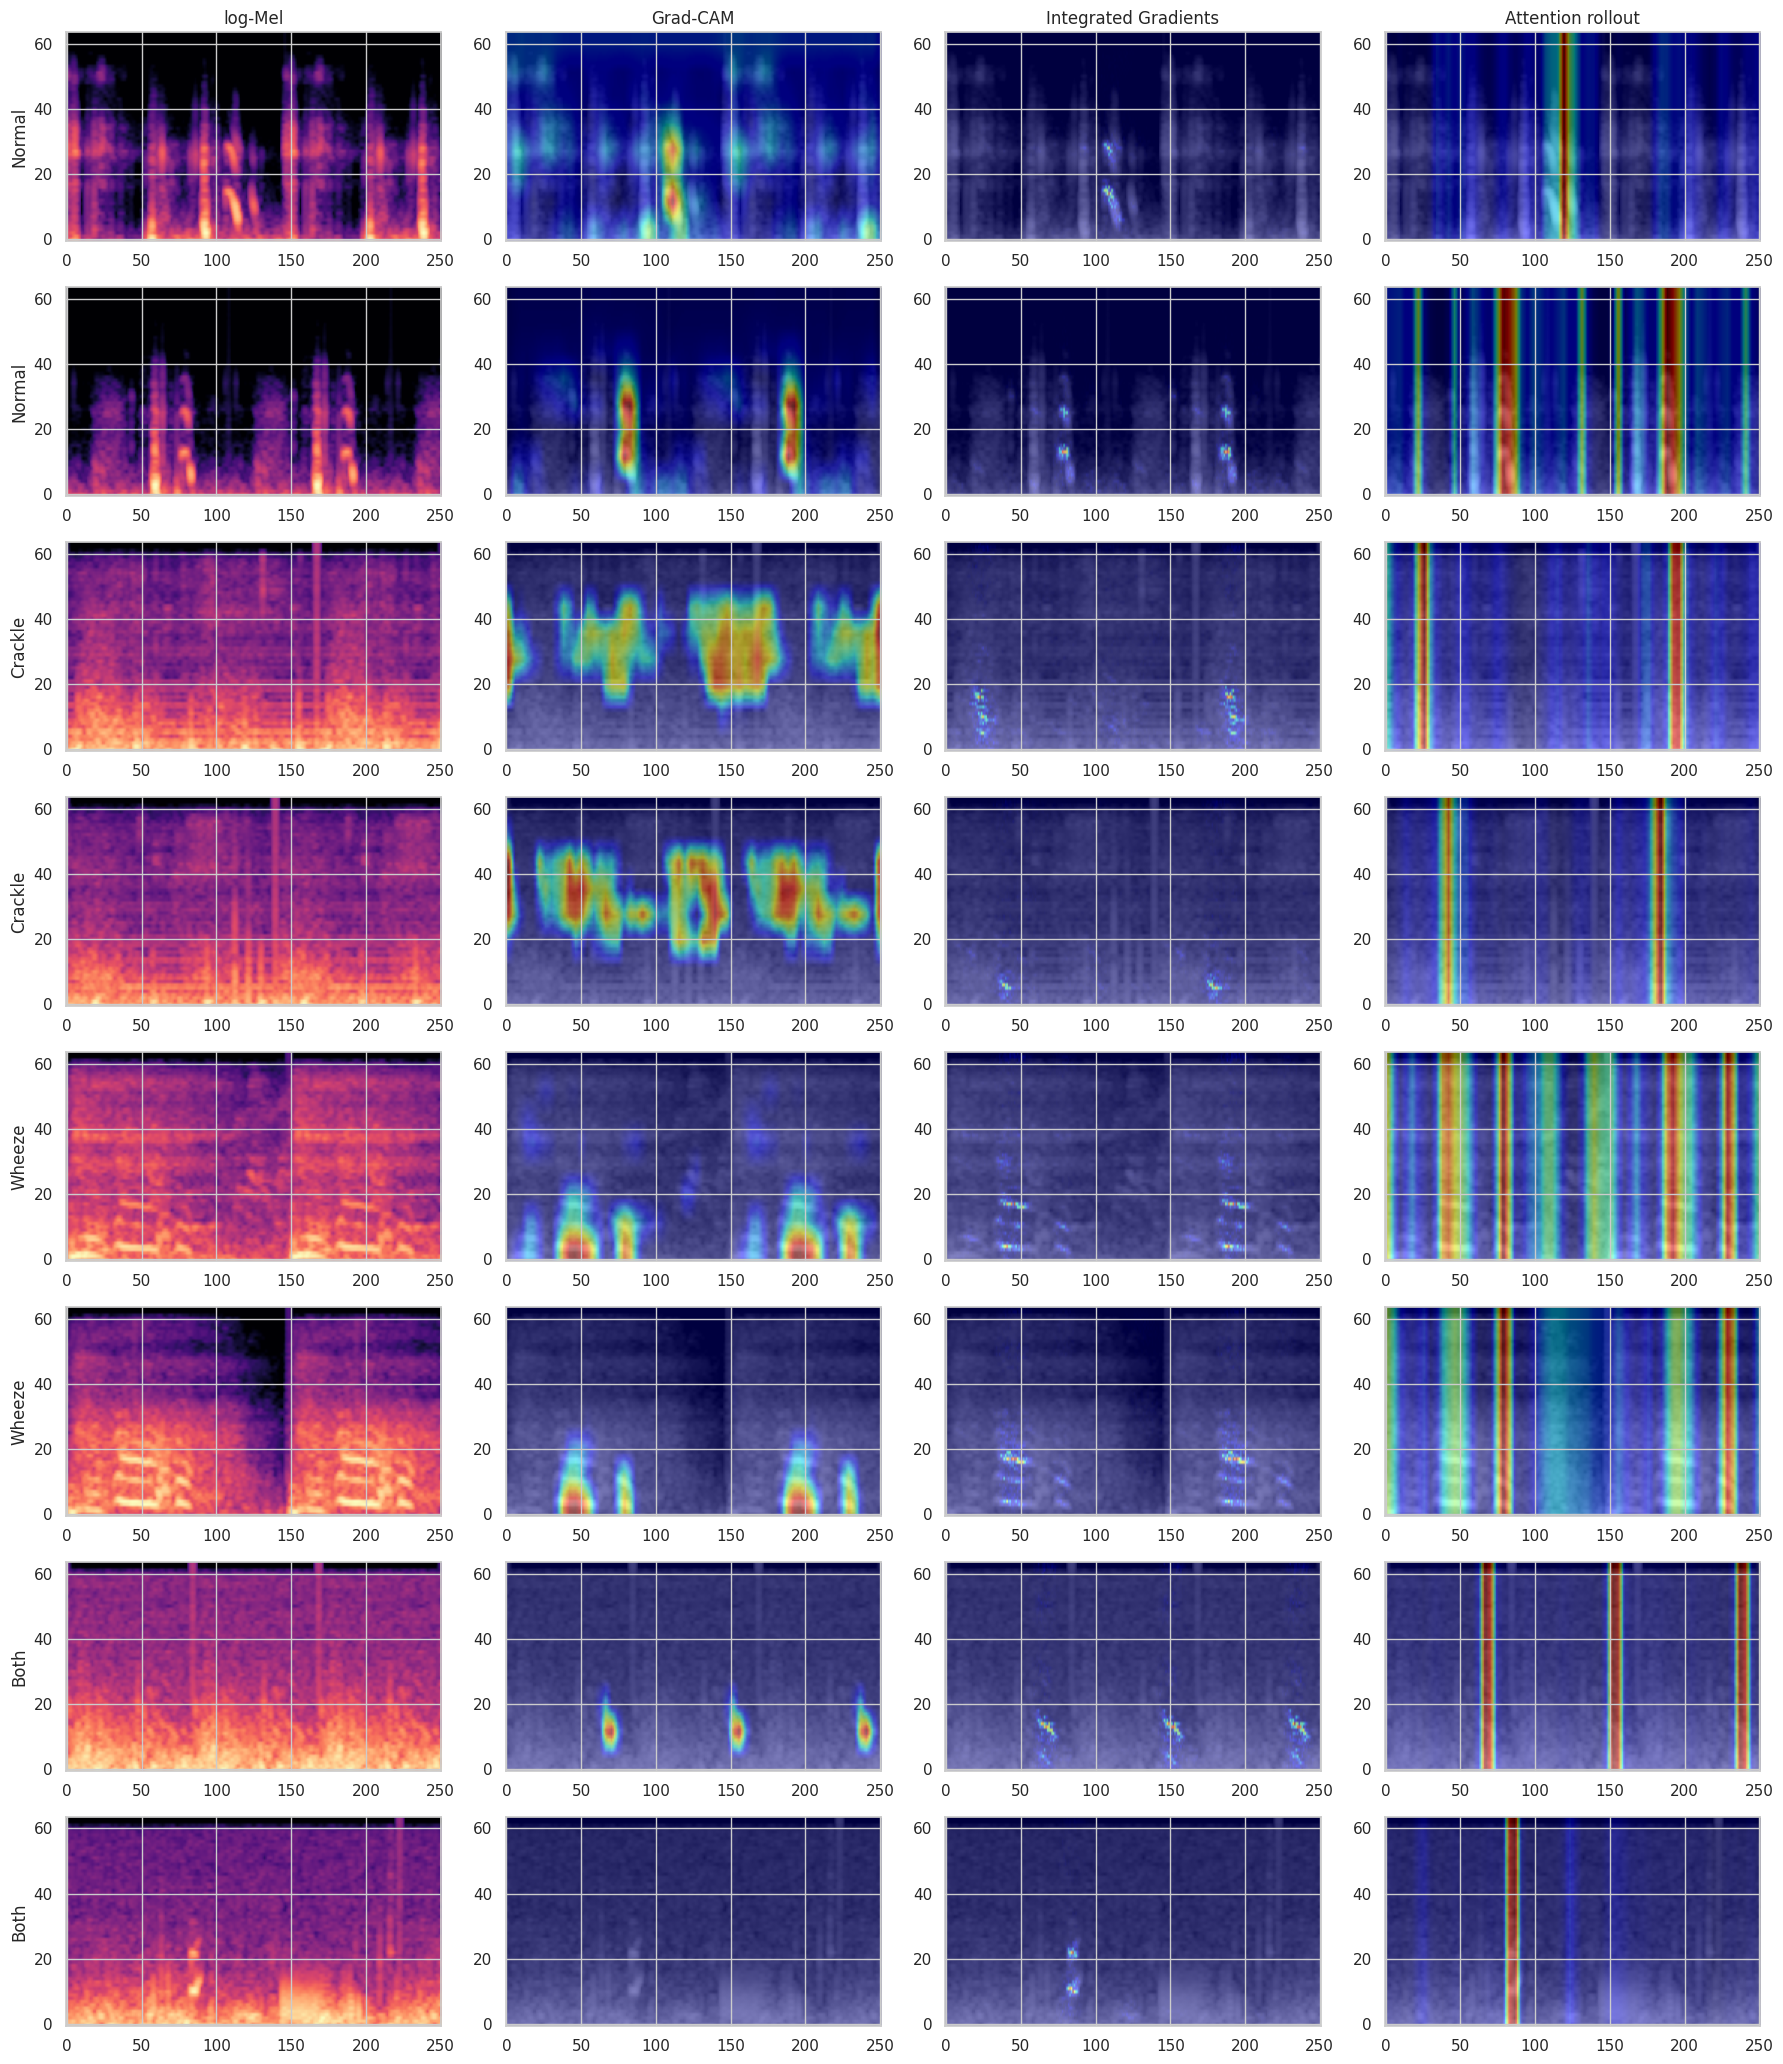

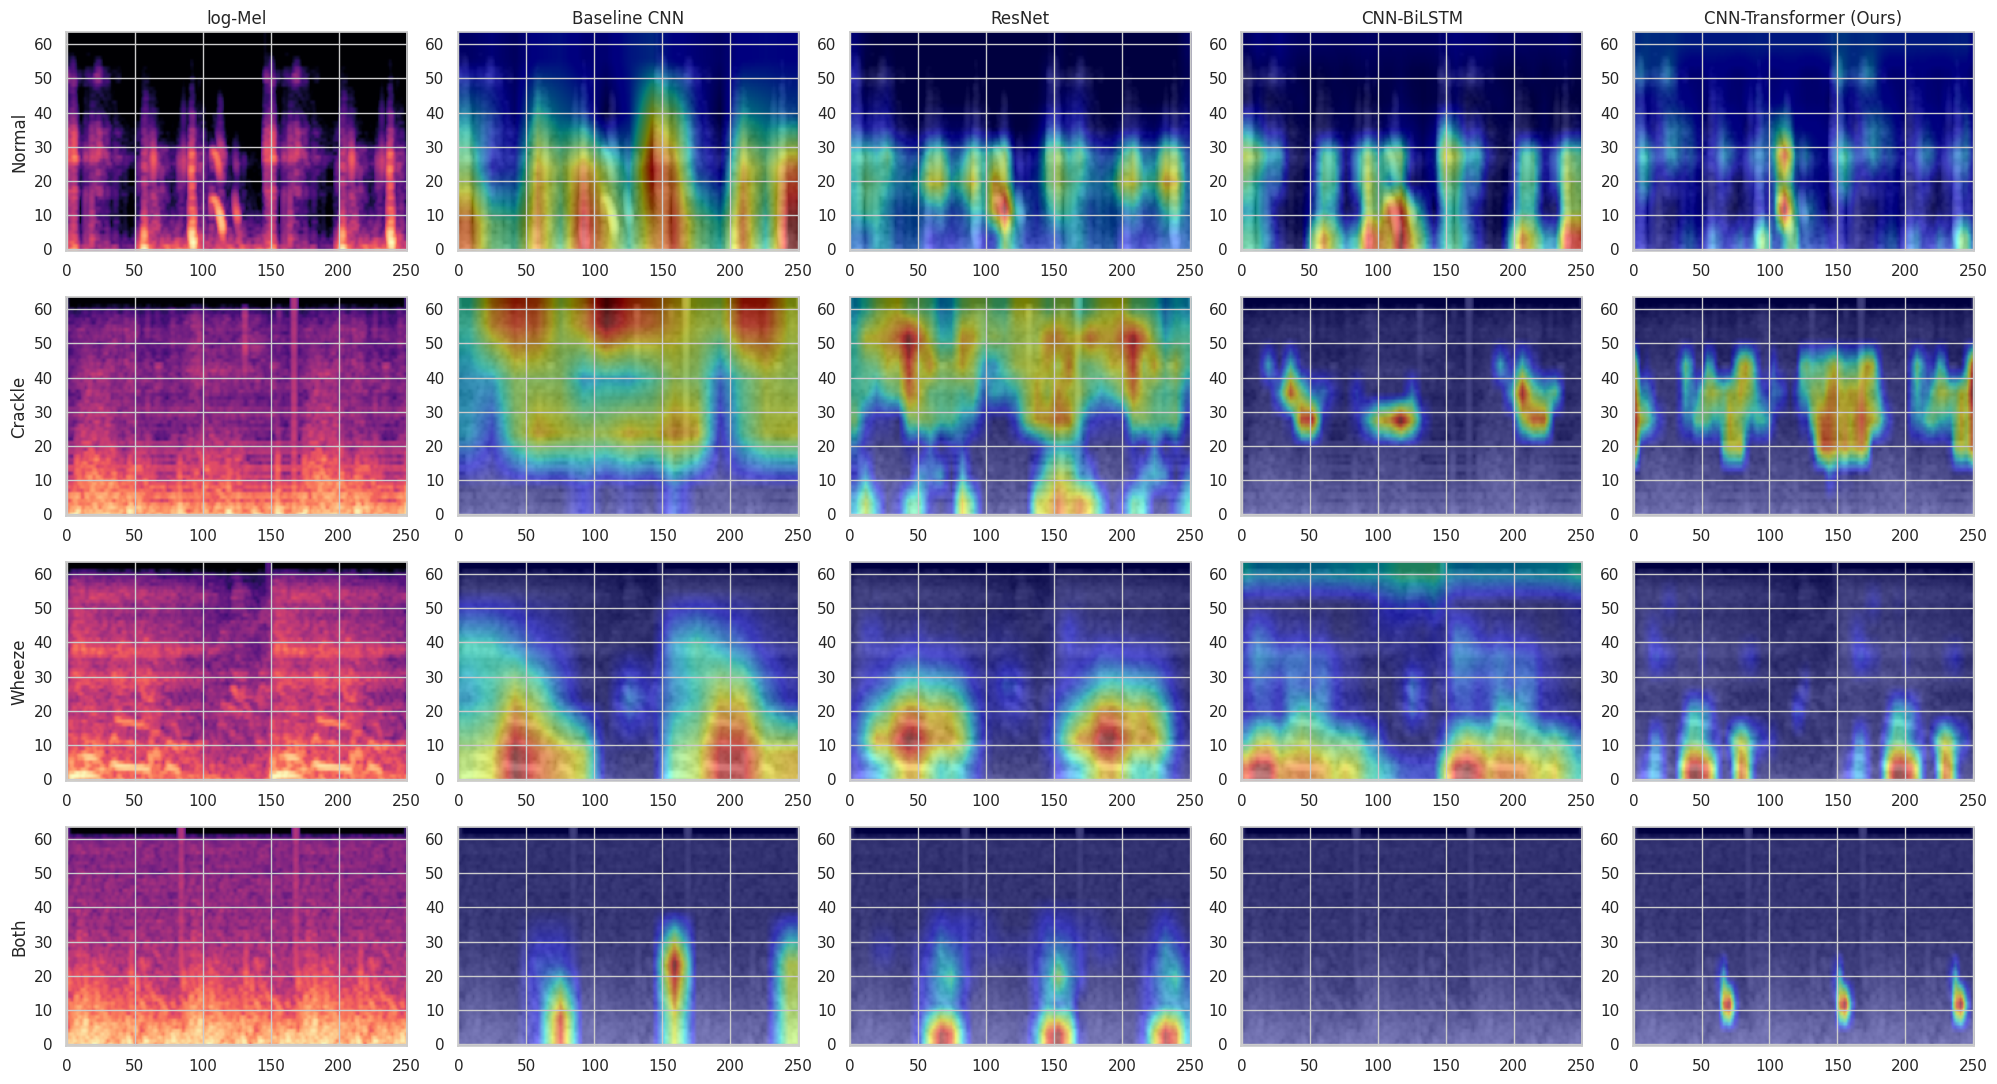

In [ ]:
def get_model(name, seed=0, fold=0):
    sp = MAIN[name]
    m = build_model(sp["arch"], **sp.get("model", {})).to(DEV)
    m.load_state_dict(CKPT[(name, seed, fold)]); return m.eval()


def grad_cam(model, spec, target):
    acts, grads = {}, {}

    def fh(m, i, o):
        acts["a"] = o
        o.register_hook(lambda g: grads.__setitem__("g", g))
    h = model.cam_layer.register_forward_hook(fh)
    with torch.backends.cudnn.flags(enabled=False):
        model.zero_grad(); x = spec.clone().requires_grad_(True)
        out = model.forward_spec(x)
        out.gather(1, target[:, None]).sum().backward()
    h.remove()
    w = grads["g"].mean((2, 3), keepdim=True)
    cam = F.relu((w * acts["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=spec.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    mn, mx = cam.amin((1, 2), keepdim=True), cam.amax((1, 2), keepdim=True)
    return ((cam - mn) / (mx - mn + 1e-8)).detach()


def integrated_gradients(model, spec, target, steps=24):
    base, tot = torch.zeros_like(spec), torch.zeros_like(spec)
    with torch.backends.cudnn.flags(enabled=False):
        for a in torch.linspace(0, 1, steps):
            x = (base + a * (spec - base)).requires_grad_(True)
            model.zero_grad()
            model.forward_spec(x).gather(1, target[:, None]).sum().backward()
            tot += x.grad
    attr = ((spec - base) * tot / steps)[:, 0].abs()
    mn, mx = attr.amin((1, 2), keepdim=True), attr.amax((1, 2), keepdim=True)
    return ((attr - mn) / (mx - mn + 1e-8)).detach()


@torch.no_grad()
def attention_rollout(model, spec):
    model.eval(); model.forward_spec(spec)
    R = None
    for l in model.layers:
        A = 0.5 * l.attn_w + 0.5 * torch.eye(l.attn_w.size(-1), device=spec.device)
        A = A / A.sum(-1, keepdim=True)
        R = A if R is None else A @ R
    r = R[:, 0, 1:]                                              # CLS -> patch tokens
    r = F.interpolate(r[:, None], size=spec.shape[-1], mode="linear", align_corners=False)[:, 0]
    r = (r - r.amin(1, keepdim=True)) / (r.amax(1, keepdim=True) - r.amin(1, keepdim=True) + 1e-8)
    return r[:, None, :].expand(-1, spec.shape[2], -1).contiguous()       # (B,F,T)


# ---- sample choose: fold-0 test, correctly classified, per class 2 ta
folds0 = make_folds(CFG.SEEDS[0])
te0 = folds0[0][2]
ours = "CNN-Transformer (Ours)"
pred0 = main_oof[(ours, CFG.SEEDS[0])].argmax(1)
sel = []
for c in range(4):
    ok = te0[(Y[te0] == c) & (pred0[te0] == c)]
    if len(ok) < 2: ok = np.concatenate([ok, te0[Y[te0] == c]])     # fallback (QUICK mode)
    sel += list(ok[:2])
sel = np.array(sel)
print("XAI samples:", sel, [CFG.CLASSES[Y[i]] for i in sel])

m_ours = get_model(ours, CFG.SEEDS[0], 0)
fe = fe.eval()
with torch.no_grad(): S = fe(XG[sel])
tgt = torch.tensor(Y[sel], device=DEV)
cam_o = grad_cam(m_ours, S, tgt).cpu().numpy()
ig_o = integrated_gradients(m_ours, S, tgt).cpu().numpy()
att_o = attention_rollout(m_ours, S).cpu().numpy()
S_np = S[:, 0].cpu().numpy()

fig, ax = plt.subplots(len(sel), 4, figsize=(18, 2.6 * len(sel)))
for r in range(len(sel)):
    ax[r, 0].imshow(S_np[r], origin="lower", aspect="auto", cmap="magma"); ax[r, 0].set_ylabel(CFG.CLASSES[Y[sel[r]]])
    for c, (mp, ttl) in enumerate([(cam_o, "Grad-CAM"), (ig_o, "Integrated Gradients"), (att_o, "Attention rollout")], 1):
        ax[r, c].imshow(S_np[r], origin="lower", aspect="auto", cmap="gray")
        ax[r, c].imshow(mp[r], origin="lower", aspect="auto", cmap="jet", alpha=0.5)
        if r == 0: ax[r, c].set_title(ttl)
    if r == 0: ax[r, 0].set_title("log-Mel")
plt.tight_layout(); plt.savefig(f"{CFG.WORK}/fig_xai_ours.png", dpi=150); plt.show()

# ---- Grad-CAM: model gulo compare (class per 1 sample)
cmp_names = ["Baseline CNN", "ResNet", "CNN-BiLSTM", ours]
one = np.array([sel[2 * c] for c in range(4)])
S1 = fe(XG[one]).detach(); t1 = torch.tensor(Y[one], device=DEV)
fig, ax = plt.subplots(4, 5, figsize=(20, 11))
for r in range(4):
    ax[r, 0].imshow(S1[r, 0].cpu(), origin="lower", aspect="auto", cmap="magma")
    ax[r, 0].set_ylabel(CFG.CLASSES[Y[one[r]]])
for ci, nm in enumerate(cmp_names, 1):
    cm_ = grad_cam(get_model(nm, CFG.SEEDS[0], 0), S1, t1).cpu().numpy()
    for r in range(4):
        ax[r, ci].imshow(S1[r, 0].cpu(), origin="lower", aspect="auto", cmap="gray")
        ax[r, ci].imshow(cm_[r], origin="lower", aspect="auto", cmap="jet", alpha=0.5)
        if r == 0: ax[r, ci].set_title(nm)
ax[0, 0].set_title("log-Mel")
plt.tight_layout(); plt.savefig(f"{CFG.WORK}/fig_xai_compare.png", dpi=150); plt.show()

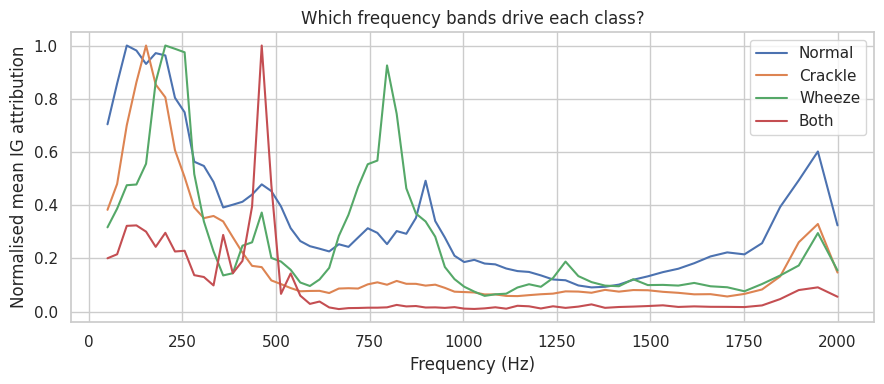

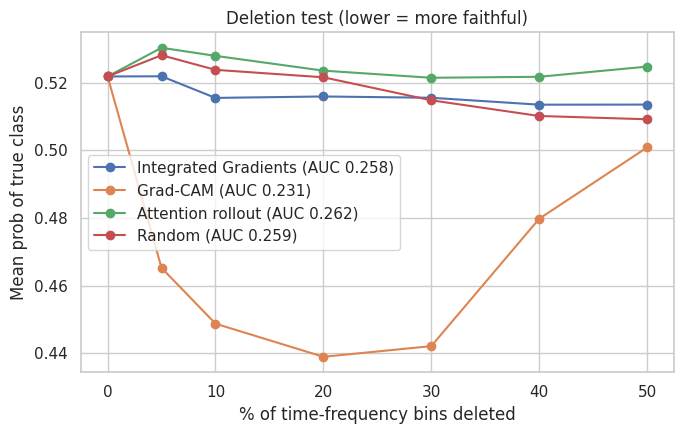

In [ ]:
# ---- class-wise frequency importance (IG) + deletion faithfulness test
pool = te0[pred0[te0] == Y[te0]]
if len(pool) < 8: pool = te0
pool = np.random.RandomState(0).choice(pool, min(96, len(pool)), replace=False)
Sp_, tp_ = fe(XG[pool]).detach(), torch.tensor(Y[pool], device=DEV)
ig_all = torch.cat([integrated_gradients(m_ours, Sp_[i:i + 24], tp_[i:i + 24], 16) for i in range(0, len(pool), 24)])
cam_all = torch.cat([grad_cam(m_ours, Sp_[i:i + 24], tp_[i:i + 24]) for i in range(0, len(pool), 24)])
att_all = torch.cat([attention_rollout(m_ours, Sp_[i:i + 24]) for i in range(0, len(pool), 24)])

mel_hz = librosa.mel_frequencies(n_mels=CFG.N_MELS, fmin=CFG.FMIN, fmax=CFG.FMAX)
plt.figure(figsize=(9, 4))
for c in range(4):
    sel_c = (Y[pool] == c)
    if sel_c.sum() == 0: continue
    prof = ig_all[torch.tensor(sel_c, device=DEV)].mean((0, 2)).cpu().numpy()
    plt.plot(mel_hz, prof / prof.max(), label=CFG.CLASSES[c])
plt.xlabel("Frequency (Hz)"); plt.ylabel("Normalised mean IG attribution"); plt.legend()
plt.title("Which frequency bands drive each class?"); plt.tight_layout()
plt.savefig(f"{CFG.WORK}/fig_xai_freq.png", dpi=150); plt.show()


@torch.no_grad()
def deletion_curve(model, spec, cls, attr, fracs):
    B, _, Fq, T = spec.shape
    order = attr.reshape(B, -1).argsort(1, descending=True); res = []
    for f in fracs:
        k = int(f * Fq * T); m = torch.zeros(B, Fq * T, dtype=torch.bool, device=spec.device)
        if k > 0: m.scatter_(1, order[:, :k], True)
        p = F.softmax(model.forward_spec(spec.masked_fill(m.view(B, 1, Fq, T), 0.0)), 1)
        res.append(p.gather(1, cls[:, None]).mean().item())
    return res


_trapz = getattr(np, "trapezoid", None) or np.trapz
fracs = [0, .05, .1, .2, .3, .4, .5]
rnd = torch.rand_like(ig_all)
curves = {"Integrated Gradients": ig_all, "Grad-CAM": cam_all, "Attention rollout": att_all, "Random": rnd}
plt.figure(figsize=(7, 4.5))
for nm, a in curves.items():
    cv = deletion_curve(m_ours, Sp_, tp_, a, fracs)
    plt.plot([f * 100 for f in fracs], cv, marker="o", label=f"{nm} (AUC {_trapz(cv, fracs):.3f})")
plt.xlabel("% of time-frequency bins deleted"); plt.ylabel("Mean prob of true class")
plt.title("Deletion test (lower = more faithful)"); plt.legend(); plt.tight_layout()
plt.savefig(f"{CFG.WORK}/fig_xai_deletion.png", dpi=150); plt.show()

# 9. Ablation study (proposed CNN-Transformer)

[seed 0 fold 0] w/o CNN stem (patchify)          Score 0.500  (3s)
[seed 0 fold 0] w/o Transformer (CNN+pool)       Score 0.515  (16s)
[seed 0 fold 0] w/o positional enc.              Score 0.555  (17s)
[seed 0 fold 0] w/o SE attention                 Score 0.466  (15s)
[seed 0 fold 0] w/o [CLS] (mean pool)            Score 0.471  (15s)
[seed 0 fold 0] 1 encoder layer                  Score 0.499  (15s)
[seed 0 fold 0] 4 encoder layers                 Score 0.465  (17s)
[seed 0 fold 0] w/o SpecAugment                  Score 0.475  (16s)
[seed 0 fold 0] w/o class weighting              Score 0.480  (16s)
[seed 0 fold 1] w/o CNN stem (patchify)          Score 0.524  (3s)
[seed 0 fold 1] w/o Transformer (CNN+pool)       Score 0.510  (13s)
[seed 0 fold 1] w/o positional enc.              Score 0.514  (13s)
[seed 0 fold 1] w/o SE attention                 Score 0.467  (12s)
[seed 0 fold 1] w/o [CLS] (mean pool)            Score 0.473  (13s)
[seed 0 fold 1] 1 encoder layer                  S

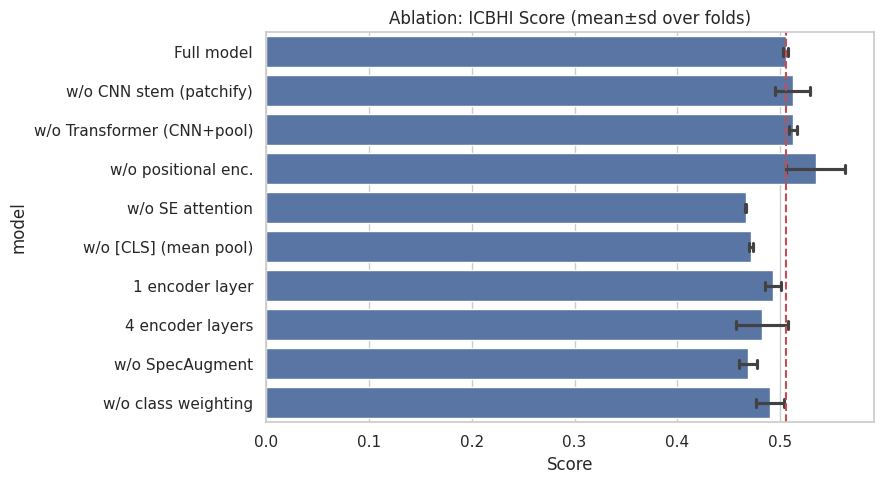

In [ ]:
ABL = {
    "w/o CNN stem (patchify)": dict(arch="proposed", model=dict(use_cnn=False)),
    "w/o Transformer (CNN+pool)": dict(arch="proposed", model=dict(use_transformer=False)),
    "w/o positional enc.":     dict(arch="proposed", model=dict(use_pos=False)),
    "w/o SE attention":        dict(arch="proposed", model=dict(use_se=False)),
    "w/o [CLS] (mean pool)":   dict(arch="proposed", model=dict(use_cls=False)),
    "1 encoder layer":         dict(arch="proposed", model=dict(n_layers=1)),
    "4 encoder layers":        dict(arch="proposed", model=dict(n_layers=4)),
    "w/o SpecAugment":         dict(arch="proposed", train=dict(specaug=False)),
    "w/o class weighting":     dict(arch="proposed", train=dict(class_weight=False)),
}
abl_df, abl_oof, abl_cover, _ = run_experiment(ABL, noise=False)
full = main_df[(main_df.model == ours) & (main_df.cond == "clean")].copy(); full["model"] = "Full model"
abl_all = pd.concat([full, abl_df], ignore_index=True)
for s in CFG.SEEDS: abl_oof[("Full model", s)] = main_oof[(ours, s)]
abl_all.to_csv(f"{CFG.WORK}/results_ablation.csv", index=False)

order = ["Full model"] + list(ABL)
ab_tab = abl_all.groupby("model")[["Sp", "Se", "Score", "MacroF1", "Acc"]].mean().loc[order]
ab_tab["ΔScore vs Full"] = ab_tab.Score - ab_tab.loc["Full model", "Score"]
ab_tab["ΔF1 vs Full"] = ab_tab.MacroF1 - ab_tab.loc["Full model", "MacroF1"]
print(ab_tab.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=abl_all, y="model", x="Score", order=order, errorbar="sd", ax=ax, capsize=.2)
ax.axvline(ab_tab.loc["Full model", "Score"], c="r", ls="--"); ax.set_title("Ablation: ICBHI Score (mean±sd over folds)")
plt.tight_layout(); plt.savefig(f"{CFG.WORK}/fig_ablation.png", dpi=150); plt.show()

# 10. Statistical analysis
1. Mean±SD across patient-wise folds  2. Patient-cluster bootstrap 95% CI (pooled out-of-fold)
3. Paired Wilcoxon (per seed×fold) + Holm correction + Cohen's dz  4. Friedman test
5. Paired patient-bootstrap difference test  6. McNemar (cycle-level, non-independence caveat)

=== Mean ± SD over folds (clean) ===
                                       Sp             Se          Score  \
model                                                                     
Baseline CNN                0.776 ± 0.106  0.286 ± 0.116  0.531 ± 0.005   
CNN-BiLSTM                  0.832 ± 0.238  0.158 ± 0.224  0.495 ± 0.007   
CNN-Transformer (Ours)      0.748 ± 0.101  0.263 ± 0.096  0.505 ± 0.003   
CNN-Transformer + NoiseAug  0.871 ± 0.061  0.156 ± 0.104  0.513 ± 0.022   
ResNet                      0.764 ± 0.122  0.282 ± 0.181  0.523 ± 0.029   

                                  MacroF1            Acc  
model                                                     
Baseline CNN                0.305 ± 0.012   0.541 ± 0.01  
CNN-BiLSTM                  0.224 ± 0.068  0.517 ± 0.033  
CNN-Transformer (Ours)      0.308 ± 0.066  0.516 ± 0.003  
CNN-Transformer + NoiseAug   0.25 ± 0.046  0.533 ± 0.002  
ResNet                      0.354 ± 0.066  0.539 ± 0.011  

=== Pooled out-of-fold,

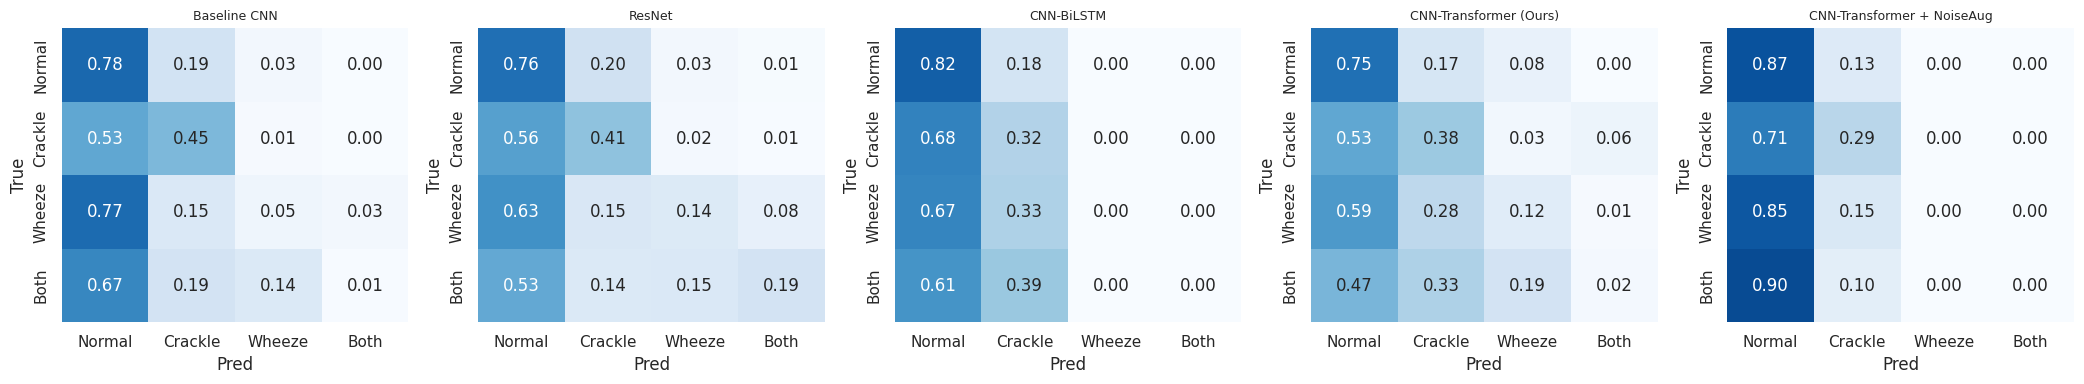


Done. Outputs saved in /kaggle/working


In [ ]:
def holm(pvals):
    p = np.asarray(pvals, float); o = np.argsort(p); adj = np.empty_like(p); run = 0
    for rank, i in enumerate(o):
        run = max(run, (len(p) - rank) * p[i]); adj[i] = min(run, 1.0)
    return adj


def paired_tests(df, ref, others, cond="clean", metric="Score"):
    d = df[df.cond == cond] if "cond" in df else df
    pv = d.pivot_table(index=["seed", "fold"], columns="model", values=metric)
    out = []
    for o in others:
        diff = (pv[ref] - pv[o]).dropna().values
        try: p = stats.wilcoxon(diff).pvalue
        except ValueError: p = 1.0
        out.append(dict(comparison=f"{ref} vs {o}", n_pairs=len(diff), mean_diff=diff.mean(),
                        dz=diff.mean() / (diff.std(ddof=1) + 1e-12) if len(diff) > 1 else np.nan, p_wilcoxon=p))
    r = pd.DataFrame(out); r["p_holm"] = holm(r.p_wilcoxon.values) if len(r) else []
    return r


# ---- 10.1 mean±sd table
def mean_sd(df, cond="clean"):
    g = df[df.cond == cond].groupby("model")[["Sp", "Se", "Score", "MacroF1", "Acc"]]
    m, s = g.mean(), g.std()
    return (m.round(3).astype(str) + " ± " + s.round(3).astype(str))


print("=== Mean ± SD over folds (clean) ===")
print(mean_sd(main_df))

# ---- 10.2 pooled OOF + patient-cluster bootstrap
seed0 = CFG.SEEDS[0]
cover = main_cover[seed0]
yc, pidc = Y[cover], PID[cover]
pats = np.unique(pidc)
preds = {m: main_oof[(m, seed0)][cover].argmax(1) for m in MAIN}
pat_cm = {m: np.stack([np.bincount(yc[pidc == p] * 4 + preds[m][pidc == p], minlength=16) for p in pats]) for m in MAIN}
rng = np.random.default_rng(0)
NB = 2000
draws = rng.integers(0, len(pats), (NB, len(pats)))
boot = {m: pd.DataFrame([cm_metrics(c) for c in pat_cm[m][draws].sum(1)]) for m in MAIN}

rows = []
for m in MAIN:
    pt = cm_metrics(pat_cm[m].sum(0))
    row = dict(model=m)
    for k in ["Sp", "Se", "Score", "MacroF1"]:
        lo, hi = np.percentile(boot[m][k], [2.5, 97.5]); row[k] = f"{pt[k]:.3f} [{lo:.3f}, {hi:.3f}]"
    rows.append(row)
print("\n=== Pooled out-of-fold, patient-bootstrap 95% CI ===")
print(pd.DataFrame(rows).to_string(index=False))

# ---- 10.3 paired patient-bootstrap difference (ours vs others)
rows = []
for m in MAIN:
    if m == ours: continue
    for k in ["Score", "MacroF1"]:
        d = boot[ours][k] - boot[m][k]
        rows.append(dict(comparison=f"Ours vs {m}", metric=k, diff=d.mean(),
                         ci_low=np.percentile(d, 2.5), ci_high=np.percentile(d, 97.5),
                         p_boot=min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))))
pb = pd.DataFrame(rows); pb["p_holm"] = holm(pb.p_boot.values)
print("\n=== Paired patient-bootstrap: Ours - other ===")
print(pb.round(4).to_string(index=False))

# ---- 10.4 Wilcoxon / Friedman across (seed x fold)
others = [m for m in MAIN if m != ours]
print("\n=== Paired Wilcoxon (per seed×fold), Holm-corrected ===")
print(paired_tests(main_df, ours, others).round(4).to_string(index=False))
print("(NOTE: 5 pair e minimum two-sided p = 0.0625. Significance er jonno SEEDS=[0,1,2] chalao.)")

piv = main_df[main_df.cond == "clean"].pivot_table(index=["seed", "fold"], columns="model", values="Score").dropna()
if piv.shape[0] >= 3 and piv.shape[1] >= 3:
    chi, p = stats.friedmanchisquare(*[piv[c] for c in piv.columns])
    print(f"\nFriedman test (Score across models): chi2={chi:.3f}, p={p:.4f}")

# ---- 10.5 McNemar (cycle level)
rows = []
for m in others:
    a, b = preds[ours] == yc, preds[m] == yc
    n01, n10 = int((a & ~b).sum()), int((~a & b).sum())
    p = stats.binomtest(n01, n01 + n10, 0.5).pvalue if (n01 + n10) > 0 else 1.0
    rows.append(dict(comparison=f"Ours vs {m}", ours_only_correct=n01, other_only_correct=n10, p_mcnemar=p))
mc = pd.DataFrame(rows); mc["p_holm"] = holm(mc.p_mcnemar.values)
print("\n=== McNemar exact (cycle-level; same patient er cycle independent noy -> bootstrap ke prefer koro) ===")
print(mc.round(4).to_string(index=False))

# ---- 10.6 noise: paired tests per condition (ours vs ours+noiseaug vs baselines)
rows = []
for cond in ["white_10", "white_5", "white_0", "white_-5", "pink_0"]:
    t = paired_tests(main_df, "CNN-Transformer + NoiseAug", [ours, "ResNet", "CNN-BiLSTM"], cond=cond)
    t.insert(0, "cond", cond); rows.append(t)
print("\n=== Noise robustness: paired Wilcoxon (Score) ===")
print(pd.concat(rows).round(4).to_string(index=False))

# ---- 10.7 ablation: paired tests (Wilcoxon + patient bootstrap)
print("\n=== Ablation: Full vs variant (Wilcoxon on Score, Holm) ===")
print(paired_tests(abl_all.assign(cond="clean"), "Full model", list(ABL)).round(4).to_string(index=False))

abl_preds = {m: abl_oof[(m, seed0)][abl_cover[seed0]].argmax(1) for m in order}
yA, pA = Y[abl_cover[seed0]], PID[abl_cover[seed0]]
patsA = np.unique(pA)
cmA = {m: np.stack([np.bincount(yA[pA == p] * 4 + abl_preds[m][pA == p], minlength=16) for p in patsA]) for m in order}
drA = rng.integers(0, len(patsA), (NB, len(patsA)))
bA = {m: pd.Series([cm_metrics(c)["Score"] for c in cmA[m][drA].sum(1)]) for m in order}
rows = []
for m in order[1:]:
    d = bA["Full model"] - bA[m]
    rows.append(dict(variant=m, dScore=d.mean(), ci_low=np.percentile(d, 2.5), ci_high=np.percentile(d, 97.5),
                     p_boot=min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))))
ab_b = pd.DataFrame(rows); ab_b["p_holm"] = holm(ab_b.p_boot.values)
print("\n=== Ablation: paired patient-bootstrap (Score) ===")
print(ab_b.round(4).to_string(index=False))

# ---- 10.8 confusion matrices (pooled OOF)
fig, ax = plt.subplots(1, len(MAIN), figsize=(4.2 * len(MAIN), 4))
for a, m in zip(ax, MAIN):
    cm = pat_cm[m].sum(0).reshape(4, 4); cmn = cm / cm.sum(1, keepdims=True).clip(1)
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", cbar=False, xticklabels=CFG.CLASSES,
                yticklabels=CFG.CLASSES, ax=a, vmin=0, vmax=1)
    a.set_title(m, fontsize=9); a.set_xlabel("Pred"); a.set_ylabel("True")
plt.tight_layout(); plt.savefig(f"{CFG.WORK}/fig_confusion.png", dpi=150); plt.show()

# ---- save everything
main_df.to_csv(f"{CFG.WORK}/results_main.csv", index=False)
pb.to_csv(f"{CFG.WORK}/stats_bootstrap.csv", index=False)
print("\nDone. Outputs saved in", CFG.WORK)